**Лабораторный практикум по курсу «Распознавание диктора», Университет ИТМО, 2021**		

**Лабораторная работа №5. Адаптация и калибровка системы распознавания диктора**

**Цель работы:** изучение методов адаптации и калибровки, используемых на практике при решении задачи голосовой биометрии.

**Краткое описание:** в рамках настоящей лабораторной работы предлагается изучить и реализовать некоторые алгоритмы адаптации и калибровки биометрических систем. В качестве процедуры адаптации предлагается рассмотреть адаптацию на основе s-нормализации. Процедуру калибровки предлагается реализовать с помощью метода логистической регрессии. Тестирование системы голосовой биометрии после выполнения процедур адаптации и калибровки предлагается выполнить на основе метрик равновероятной ошибки и минимума функции стоимости детектирования применительно к задаче верификации.

**Данные:** в качестве данных для выполнения лабораторной работы предлагается использовать тестовую часть базы
[VoxCeleb1](http://www.robots.ox.ac.uk/~vgg/data/voxceleb/vox1.html) и [VoxCeleb2](http://www.robots.ox.ac.uk/~vgg/data/voxceleb/vox2.html).

**Содержание лабораторной работы**

1.	Подготовка данных для выполнения процедуры адаптации.  

2.	Реализация процедуры адаптации с использованием s-нормализации.  

3.	Тестирование адаптированной к некоторым условиям биометрической системы.  

4.	Подготовка данных для выполнения процедуры калибровки.  

5.	Реализация простейшего алгоритма для выполнения процедуры калибровки системы голосовой биометрии.  

6.	Тестирование калиброванной системы голосовой биометрии.  

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
sys.path.append(os.path.realpath('..'))

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

import common
from common import (
    compute_scores_cosine,
    extract_features,
    get_dcf,
    get_eer,
    get_voxceleb_filelist,
    run_voxceleb_convert,
    test_dataset_loader,
)
from exercises_blank import (
    LinearCalibrationModel,
    get_tar_imp_scores,
    plot_histograms_2sets,
    s_norm,
)
from LoadModel import load_model
from ResNetSE34V2 import MainModel


**1. Подготовка тестовых данных и протокола для проведения тестирования системы верификации диктора**

В ходе выполнения лабораторной работы необходимы *тестовые данные*, а также связанный с ними *протокол тестирования*. Данные представляют собой звукозаписи голосов людей мужского и женского пола, сохраненных в формат *wav*. Протокол тестирования организован в виде текстового файла, в каждой строчке которого содержится одна таргет- или импостор-попытка сравнения эталонной и тестовой звукозаписи (рассматривается задача *верификации диктора*, т.е. сравнение «один к одному»). Голоса эталона и теста из *таргет-попытки* (метка «1») соответствуют одному и тому же диктору, а голоса эталона и теста из *импостор-попытки* (метка «0») соответствуют разным дикторам.

Необходимые данные можно скачать по ссылкам, представленным ниже. В рамках настоящего пункта требуется:

1. Использовать локально распакованные данные звуковых wav-файлов базы [VoxCeleb1 test set](https://thor.robots.ox.ac.uk/~vgg/data/voxceleb/vox1a/vox1_test_wav.zip) и [VoxCeleb1 dev set](https://thor.robots.ox.ac.uk/~vgg/data/voxceleb/vox1a/vox2_test_wav.zip).

2. Преобразовать базу [VoxCeleb1 dev set](https://thor.robots.ox.ac.uk/~vgg/data/voxceleb/vox1a/vox2_test_wav.zip) из aac-формата в wav-формат.

3. Использовать локальный протокол тестирования [VoxCeleb1-O cleaned](https://www.robots.ox.ac.uk/~vgg/data/voxceleb/meta/veri_test2.txt).

4. Подготовить тестовые и адаптационные данные путём применения к оригинальным звукозаписям MP3-кодека. В качестве тестовых данных предлагается рассмотреть данные полученные из базы VoxCeleb1 test set, а в качестве адаптационных – из базы VoxCeleb1 dev set.

![Рисунок 1](../images/voxceleb_dataset.png "VoxCeleb. Крупномасштабная аудиовизуальная база данных человеческой речи.")

In [2]:
from common.voxceleb_paths import (
    VOX1_DEV_WAV,
    VOX1_DEV_WAV_MP3,
    VOX1_TEST_WAV,
    VOX1_TEST_WAV_MP3,
    VOX1_VERI_TEST2,
    require_voxceleb,
)

require_voxceleb(VOX1_DEV_WAV, VOX1_TEST_WAV, VOX1_VERI_TEST2)
print(f'VoxCeleb1 dev: {VOX1_DEV_WAV}')
print(f'VoxCeleb1 test: {VOX1_TEST_WAV}')
print(f'VoxCeleb1 protocol: {VOX1_VERI_TEST2}')


VoxCeleb1 dev: /home/ext-gusev-i@ad.speechpro.com/workspace/sr_labs_book/data/voxceleb1_dev/wav
VoxCeleb1 test: /home/ext-gusev-i@ad.speechpro.com/workspace/sr_labs_book/data/voxceleb1_test/wav
VoxCeleb1 protocol: /home/ext-gusev-i@ad.speechpro.com/workspace/sr_labs_book/data/voxceleb_meta/veri_test2.txt


In [3]:
def apply_mp3_codec(source_path, target_path):
    common.apply_mp3_codec(source_path, target_path)


run_voxceleb_convert(
    input_path=VOX1_TEST_WAV,
    result_path=VOX1_TEST_WAV_MP3,
    fun=apply_mp3_codec,
    threads=10,
)
run_voxceleb_convert(
    input_path=VOX1_DEV_WAV,
    result_path=VOX1_DEV_WAV_MP3,
    fun=apply_mp3_codec,
    threads=10,
)


Checking result folder
Run /home/ext-gusev-i@ad.speechpro.com/workspace/sr_labs_book/data/voxceleb1_test/wav folder processing
Finished /home/ext-gusev-i@ad.speechpro.com/workspace/sr_labs_book/data/voxceleb1_test/wav folder processing
Checking result folder
Run /home/ext-gusev-i@ad.speechpro.com/workspace/sr_labs_book/data/voxceleb1_dev/wav folder processing
Finished /home/ext-gusev-i@ad.speechpro.com/workspace/sr_labs_book/data/voxceleb1_dev/wav folder processing


**2. Вычисление дикторских моделей для эталонных и тестовых звукозаписей используемого протокола**

В рамках настоящего исследования рассматриваются 2 тестовые базы:

1. *Out-of-domain*, исходная тестовая база VoxCeleb1 test set в микрофонном канале.
2. *In-domain*, целевая тестовая база VoxCeleb1 test set, обработанная MP3-кодеком.

Аналогично лабораторной работе №4, построим дикторские модели для имеющихся тестовых баз с использованием обученного на out-of-domain тренировочном множестве (без применения MP3-кодека) для микрофонного канала нейросетевого экстрактора эмбеддингов и оценим качество полученных дикторских моделей на имеющихся in-domain и out-of-domain тестовых данных. Последовательность действий в рамках настоящего пункта должна быть следующей:

1. Описать и инициализировать модель для генерации дикторских эмбеддингов.
2. Вгрузить в инициализированную модель обученные веса.
3. Вычислить эмбеддинги для эталонных и тестовых звукозаписей для исходной тестовой базы (out-of-domain условия).
4. Повторить п.3 для второй тестовой базы (in-domain условия).

In [4]:
model = MainModel()


Embedding size is 512, encoder ASP.


In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

with open('../data/lists/models.txt', 'r') as file:
    model_urls = file.readlines()

model = load_model(
    model,
    model_urls,
    save_path='../data/models',
    device=device,
).to(device).eval()

print(f'Device: {device}')


File baseline_v2_ap.model is downloaded.
Device: cuda


In [6]:
with open(VOX1_VERI_TEST2, 'r') as file:
    protocol = file.readlines()

test_files = sorted({
    path
    for line in protocol
    for path in line.strip().split()[-2:]
})


Построим эмбеддинги для исходной базы VoxCeleb1 test, то есть out-of-domain тестовой базы.

In [7]:
test_dataset = test_dataset_loader(
    test_files,
    test_path=VOX1_TEST_WAV,
    eval_frames=500,
    num_eval=1,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)
features_out_of_domain = torch.load(
    '../data/lab5_cache/test_clean_features.pth',
    map_location='cpu',
)


Построим эмбеддинги для in-domain тестовой базы (протокол остался прежним, имена файлов тоже, поэтому список setfiles не изменился).

In [8]:
test_dataset = test_dataset_loader(
    test_files,
    test_path=VOX1_TEST_WAV_MP3,
    eval_frames=500,
    num_eval=1,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)
features_in_domain = torch.load(
    '../data/lab5_cache/test_mp3_features.pth',
    map_location='cpu',
)


**3. Формирование оценок сравнения эталонных и тестовых дикторских моделей**

Для того, чтобы автоматически принять решении о принадлежности пары сравнения «эталон-тест» к таргет- или импостор-попытке, необходимо сформировать *оценку сравнения* между эталонной и тестовой дикторскими моделями, иначе мы называем их scores (скоры). В простейшем случае подобные сравнения можно выполнить с использованием *евклидовой метрики*, *косинусной метрики* и т.п.

В рамках настоящего пункта необходимо выполнить следующее:

1. Выполнить формирование оценок сравнения эталонных и дикторских моделей с использованием любой подходящей метрики (евклидово расстояние, косинусное расстояние и т.п.).

2. Сформировать списки оценок сравнения, таргет-/импостор-меток и имен эталон-тест в триальных сравнениях.

3. Получить оценки EER и построить графики распределения для тестовых баз in-domain и out-of-domain.

Scoring progress: 100%|██████████| 37611/37611 [00:22<00:00, 1668.06it/s]


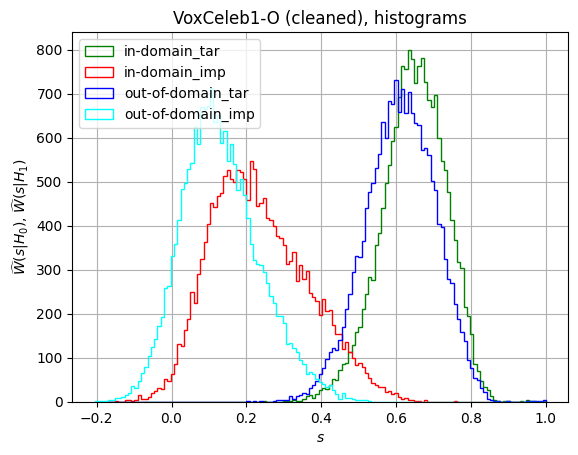

Equal Error Rate in-domain (EER): 3.723%, threshold EER: 0.485
Equal Error Rate out-of-domain (EER): 1.308%, threshold EER: 0.397


In [9]:
scores_in_domain, labels_in_domain, trials_in_domain = compute_scores_cosine(
    features_in_domain,
    protocol,
)
scores_out_of_domain, labels_out_of_domain, trials_out_of_domain = (
    compute_scores_cosine(features_out_of_domain, protocol)
)

plot_histograms_2sets(
    scores_in_domain,
    labels_in_domain,
    scores_out_of_domain,
    labels_out_of_domain,
)


**4. Доменная адаптация на основе s-нормализации**

*Доменная адаптация* рассматривается как проблема настройки параметров модели для случая когда существует большой объём нецелевых данных (out-of-domain data, source data) и малый объём размеченных или неразмеченных целевых данных (in-domain data, target data). В научно-технической литературе по распознаванию диктора часто выделяют следующие адаптационные техники: вычитание среднего, s-норма, CORAL, CORAL+, GRL, MultiReader и т.п. Важно отметить, что доменная адаптация может выполняться на всех этапах конвейера голосовой биометрии, то есть на этапе предобработки, диаризации, построения дикторской модели и т.п.

В рамках настоящей лабораторной работы рассматривается наиболее часто используемый в научно-технической литературе подход доменной адаптации, основанный на процедуре s-нормализация. 

*Адаптация с помощью s-нормы* предполагает выполнение процедуры нормализации оценок сравнения эталонов и тестов с целью уменьшения вариативности в попытках сравнения, которое ведёт к более лучшей калибровке и более надёжному выбору порога принятия решения. При выполнении адаптации на основе s-нормы необходимо выполнить следующую последовательность действий:

1. Выполнить сравнение эталонной и тестовой дикторских моделей в рамках одной попытки, получив оценку.
2. Ввести в рассмотрение импосторную когорту, состоящую из дикторских моделей, которые не пересекаются, в смысле дикторских меток, с эталонной и тестовой моделями в рамках одной попытки.
3. Сравнить эталонную дикторскую модель с каждой моделью из импосторной когорты, получив оценки сравнения; упорядочить оценки сравнения по убыванию схожести моделей; выбрать первые $N$ оценок (самые сложные оценки сравнения) и вычислить для них среднее, $\mu_e$, и среднеквадратическое отклонение, $\sigma_e$.
4. Повторить процедуру выше для тестовой дикторской модели, получив значения $\mu_t$ и $\sigma_t$.
5. Выполнить нормализацию оценки сравнения $S$ для рассматриваемой попытки: $\hat{S}=\frac{S - \mu_e}{2\sigma_e} + \frac{S - \mu_t}{2\sigma_t}$.

В рамках настоящего пункта необходимо реализовать этапы, описанные выше. Как и ранее, предполагается, что данные из базы VoxCeleb1 dev set будут использоваться в качестве адаптационного множества. Поскольку основу адаптации с помощью s-нормы составляет импосторная когорта, то искажённые под целевые условия данные из базы VoxCeleb1 dev set в рамках настоящего пункта предполагается использовать для построения этой когорты. При при проведении тестов в одном случае база VoxCeleb1 test set будет рассматривается в оригинальном виде, а в другом – в искажённом, в котором предполагается, что выбранное искажение моделирует целевые условия. Итогом выполнения настоящего пункта является оценка качества полученного после адаптации к целевым условиям верификационного решения. Качество предлагается проанализировать с использованием метрики EER и гистограмм распределения таргет- и импостор-оценок.

In [10]:
adaptation_files = sorted(get_voxceleb_filelist(VOX1_DEV_WAV_MP3))
adaptation_dataset = test_dataset_loader(
    adaptation_files,
    test_path=VOX1_DEV_WAV_MP3,
    eval_frames=1000,
    num_eval=1,
)
adaptation_loader = DataLoader(
    adaptation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)
adaptation_features = torch.load(
    '../data/lab5_cache/dev_mp3_features.pth',
    map_location='cpu',
)


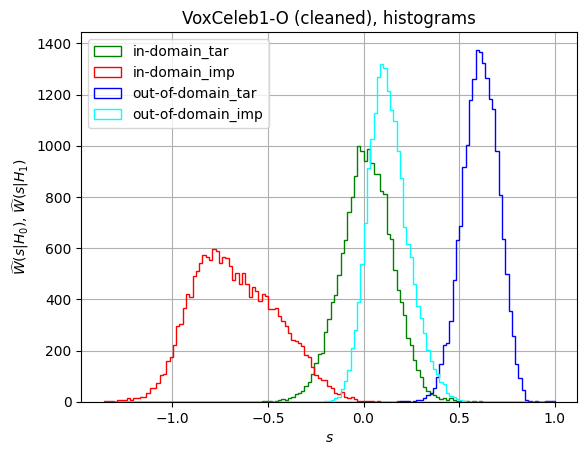

Equal Error Rate in-domain (EER): 2.929%, threshold EER: -0.242
Equal Error Rate out-of-domain (EER): 1.308%, threshold EER: 0.397


In [11]:
normalized_scores, normalized_labels, normalized_trials = s_norm(
    features_in_domain,
    protocol,
    adaptation_features,
    N_s=100,
    eps=0.6,
)

plot_histograms_2sets(
    normalized_scores,
    normalized_labels,
    scores_out_of_domain,
    labels_out_of_domain,
)


**5. Калибровка системы голосовой биометрии**

Результатом процедуры сравнения дикторских моделей являются «сырые» оценки сравнения. Основными проблемами при использовании «сырых» оценок являются:

1. Порог принятия решения для выбранной рабочей точки полностью привязан к системе распознавания диктора (если существует $N$ систем, то существует $N$ порогов).
2. Для произвольной выходной оценки сравнения нет информации о вероятности принадлежности к статистическим гипотезам.
3. Сложно учесть влияние параметров качества речевого сигнала на выходные оценки.

*Калибровка* является решением указанных проблем. Необходимость калибровки в сообществе по распознаванию диктора обусловлена следующим:

1. Представление оценок сравнения в калиброванном виде для конкурсов, например, NIST SRE. Качество калибровки учитывается наравне с качеством верификации.
2. В коммерческих системах распознавания по голосу, так как на практике для заданной оценки сравнения важно знать вероятность статистической гипотезы.

В простейшем случае модель калибровки для системы распознавания диктора может быть описаны в виде линейной функциональной зависимости: $S_c = aS + b$. Здесь $a$ и $b$ – это параметры линейной модели калибровки, $S$ – это «сырое» значение оценки сравнения, а $S_c$ – значение оценки сравнения после калибровки.

Для обучения параметров $a$ и $b$ линейной модели калибровки можно воспользоваться стоимостной функцией для *логистической регресии*. Можно доказать, что при решении задачи верификации апостериорная вероятность принадлежности пары сравнения «эталон-тест» к таргет-паре (нулевая гипотеза, $H_0$) для заданного значения калиброванной оценки сравнения эталона и теста может быть выражена следующим образом: $P(H_0|S_c) = \frac{1}{1 + e^{-S_c + T_{act}^{LLR}}}$. Здесь $T_{act}^{LLR}$ – это величина оптимального порога принятия решения в пространстве логарифма отношения правдоподобия. Фактически, величина $T_{act}^{LLR}$ задаёт желаемую теоретически рабочую точку биометрической системы. Обычно в научно-технической литературе по распознаванию диктора величина $T_{act}^{LLR}$ задается в следующем виде: $T_{act}^{LLR} = ln\left ( \frac{1 - P(H_0)}{P(H_0)} \right )$. Здесь $P(H_0)$ – это априорная вероятность таргет-гипотезы. Аналогичным образом, что и выше, можно записать апостериорную вероятность принадлежности пары сравнения «эталон-тест» к импостор-паре (альтернативная гипотеза, $H_1$) для заданного значения калиброванной оценки сравнения эталона и теста: $P(H_1|S_c) = \frac{1}{1 + e^{S_c - T_{act}^{LLR}}}$. Предполагая, что априорные вероятность выпадения таргет- и импостор-попыток равны $P(H_0)$ и $P(H_1)$, соответственно, можно записать следующее выражение для стоимостной функции, которая позволит путём численной оптимизации, вычислить оптимальные значения параметров $a$ и $b$ через минимизацию стоимостной функции:

$$J(a,b) = \frac{P(H_0)}{N_0}\sum_{i=1}^{N_0}ln\left ( 1 + e^{-(aS_i + b) + T_{act}^{LLR}} \right ) + \frac{1 - P(H_0)}{N_1}\sum_{i=1}^{N_1}ln\left ( 1 + e^{aS_i + b - T_{act}^{LLR}} \right ),$$

где $N_0$ и $N_1$ – это количество таргет- и импостор-пар в калибровочном протоколе для верификации, который необходимо подготовить отдельно перед обучением калибровочной модели. Попытки сравнения «эталон-тест» в калибровочном протоколе должны быть схожими с теми, что будут встречаться при практическом использовании итоговой системы распознавания диктора, в смысле длительностей эталонной и тестовой звукозаписей, условий записи фонограмм и т.п.

Для оценки качества модели калибровки системы голосовой биометрии можно воспользоваться подходом представленным ниже.

Пусть в настоящей лабораторной работе *байесовский риск* задан в следующем виде: $\overline{C} = P(D_1|H_0)P(H_0) + P(D_0|H_1)P(H_1)/P(H_0)$. Здесь $P(D_1|H_0)$ – это вероятность ошибки первого рода, а $P(D_0|H_1)$ – вероятность ошибки второго рода. Биометрическая система считается откалиброванной, если практический минимум байесовского риска, $\overline{C}_{min}$, вычисленный в эмпирически подобранном пороге $T_{min}^{LLR}$ по отношению к некоторому протоколу тестирования для задачи верификации, совпадает с теоретическим минимум байесовского риска, $\overline{C}_{act}$, вычисленным в точке $T_{act}^{LLR}$.

В рамках настоящего пункта необходимо обучить линейную модель калибровки. Для решения указанной задачи необходимо выполнить следующие действия:

1. Подготовить калибровочный протокол для обучения модели калибровки.
2. Задать рабочую точку, которая определит величину $T_{act}^{LLR}$.
3. Обучить калибровочную модель путём минимизации стоимостной функции для логистической регрессии с использованием методов численной оптимизации первого порядка.
4. Посчитать значения $\overline{C}_{min}$ и $\overline{C}_{act}$, а также $T_{min}^{LLR}$ и $T_{act}^{LLR}$ для выбранных протоколов тестирования до выполнения и после выполнения процедуры калибровки.

In [12]:
calibration_model = LinearCalibrationModel()
checkpoint = torch.load(
    '../data/lab5_models/lab5_calibration.pth',
    map_location='cpu',
)
target_prior = checkpoint['target_prior']
calibration_model.load_state_dict(checkpoint['model'])
calibration_model.eval()

weight = calibration_model.calib_params.weight.item()
bias = calibration_model.calib_params.bias.item()
print(f'Calibration: score -> {weight:.4f} * score + {bias:.4f}')


Calibration: score -> 5.7962 * score + -2.1266


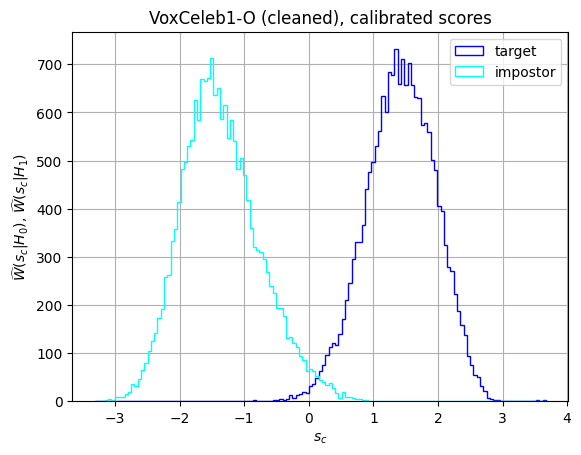

In [13]:
target_test_scores, impostor_test_scores = get_tar_imp_scores(
    scores_out_of_domain,
    labels_out_of_domain,
)

calibration_model.eval()
with torch.no_grad():
    calibrated_target_scores = calibration_model(
        torch.as_tensor(target_test_scores, dtype=torch.float32)
    ).squeeze().numpy()
    calibrated_impostor_scores = calibration_model(
        torch.as_tensor(impostor_test_scores, dtype=torch.float32)
    ).squeeze().numpy()

lower = min(calibrated_target_scores.min(), calibrated_impostor_scores.min())
upper = max(calibrated_target_scores.max(), calibrated_impostor_scores.max())
plt.hist(
    calibrated_target_scores,
    max(10, int(np.sqrt(len(calibrated_target_scores)))),
    histtype='step',
    color='blue',
    range=(lower, upper),
    label='target',
)
plt.hist(
    calibrated_impostor_scores,
    max(10, int(np.sqrt(len(calibrated_impostor_scores)))),
    histtype='step',
    color='cyan',
    range=(lower, upper),
    label='impostor',
)
plt.xlabel('$s_c$')
plt.ylabel('$\\widehat{W}(s_c|H_0)$, $\\widehat{W}(s_c|H_1)$')
plt.title('VoxCeleb1-O (cleaned), calibrated scores')
plt.legend()
plt.grid()
plt.show()


In [14]:
eer_before, _ = get_eer(target_test_scores, impostor_test_scores)
min_dcf_before, _, act_dcf_before, _ = get_dcf(
    target_test_scores,
    impostor_test_scores,
    P_target=target_prior,
)
print(
    f'Before calibration: EER={eer_before:.3f}%, '
    f'minDCF={min_dcf_before:.4f}, actDCF={act_dcf_before:.4f}'
)


Before calibration: EER=1.308%, minDCF=0.0258, actDCF=0.9115


In [15]:
eer_after, _ = get_eer(
    calibrated_target_scores,
    calibrated_impostor_scores,
)
min_dcf_after, _, act_dcf_after, _ = get_dcf(
    calibrated_target_scores,
    calibrated_impostor_scores,
    P_target=target_prior,
)
print(
    f'After calibration: EER={eer_after:.3f}%, '
    f'minDCF={min_dcf_after:.4f}, actDCF={act_dcf_after:.4f}'
)


After calibration: EER=1.308%, minDCF=0.0258, actDCF=0.0297


**Полученные результаты**

| Этап | EER | minDCF | actDCF |
|---|---:|---:|---:|
| Исходная in-domain система | 3.723% | – | – |
| После s-нормализации | 2.929% | – | – |
| До калибровки | 1.308% | 0.0258 | 0.9115 |
| После калибровки | 1.308% | 0.0258 | 0.0297 |

S-нормализация уменьшила EER на 0.794 процентного пункта. Линейная калибровка не изменила ранжирование оценок и поэтому сохранила EER и minDCF, но приблизила фактическую стоимость `actDCF` к минимально достижимой.


**6. Контрольные вопросы**
							
1. Что такое доменная адаптация?
2. Как выполнить процедуру адаптации на основе s-нормализации?
3. Для какой цели решается задача калибровки?
4. Что такое «хорошая» калибровка?
5. Какие модели калибровки систем голосовой биометрии рассматриваются на практике?
6. Как обучить калибровочную модель с использованием метода логистической регресии?

**7. Список литературы**

1. Matějka P., Novotný O., Plchot O., Burget L., Sánchez M.D., Černocký J. Analysis of score normalization in multilingual speaker recognition // Proc. Interspeech 2017, 2017. P. 1567–1571 ([ссылка](https://www.isca-speech.org/archive/pdfs/interspeech_2017/matejka17_interspeech.pdf)).

2. Gusev A., Volokhov V., Vinogradova A., Andzhukaev T., Shulipa A., Novoselov S., Pekhovsky T., Kozlov A. STC-Innovation speaker recognition systems for far-field speaker verification challenge 2020 // Proc. Interspeech 2020, 2020. P. 3466–3470 ([ссылка](https://www.isca-speech.org/archive/pdfs/interspeech_2020/gusev20_interspeech.pdf)).

3. Brümmer N., Villiers E. The BOSARIS toolkit: theory, algorithms and code for surviving the new DCF // arXiv:1304.2865 [stat.AP] ([ссылка](https://arxiv.org/pdf/1304.2865.pdf)).

4. Mandasari M.I., Saeidi R., McLaren M., Leeuwen D. Quality measure functions for calibration of speaker recognition systems in various duration conditions // IEEE Trans. Audio Speech and Language Processing, 2013. V. 21. №11. P. 2425–2438 ([ссылка](https://www.researchgate.net/publication/260695687_Quality_Measure_Functions_for_Calibration_of_Speaker_Recognition_Systems_in_Various_Duration_Conditions)).